In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
import torch

## Function basis

In [2]:
# load the curves and apply PCA
functions = np.load('data/functions.npy')
x = 0.06 * np.arange(functions.shape[1])

pca = PCA(svd_solver='full').fit(functions)
variance = np.cumsum(pca.explained_variance_ratio_)
F = np.searchsorted(variance, 0.95) + 1

print('Number of basis functions:', F)

Number of basis functions: 5


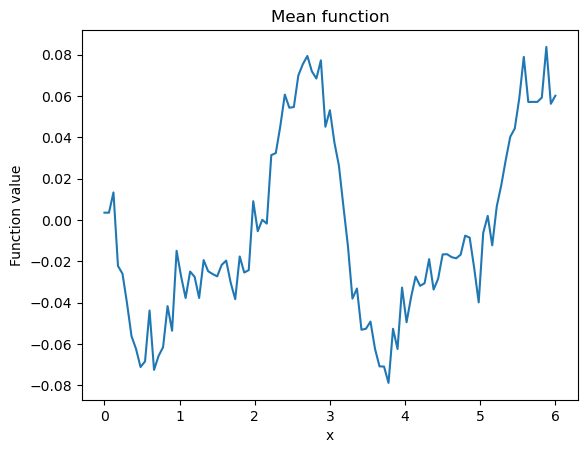

In [3]:
# mean curve
plt.figure()
plt.plot(x, pca.mean_)
plt.xlabel('x')
plt.ylabel('Function value')
plt.title('Mean function')
plt.show()

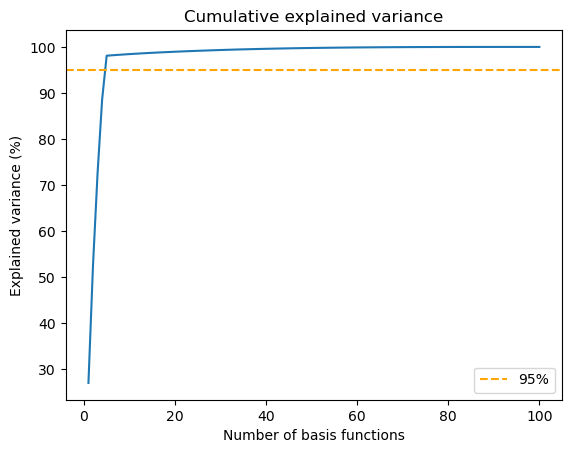

In [4]:
# explained variance
plt.figure()
plt.plot(np.arange(1, len(variance) + 1), 100 * variance)
plt.axhline(95, color='orange', linestyle='--', label='95%')
plt.xlabel('Number of basis functions')
plt.ylabel('Explained variance (%)')
plt.title('Cumulative explained variance')
plt.legend()
plt.show()

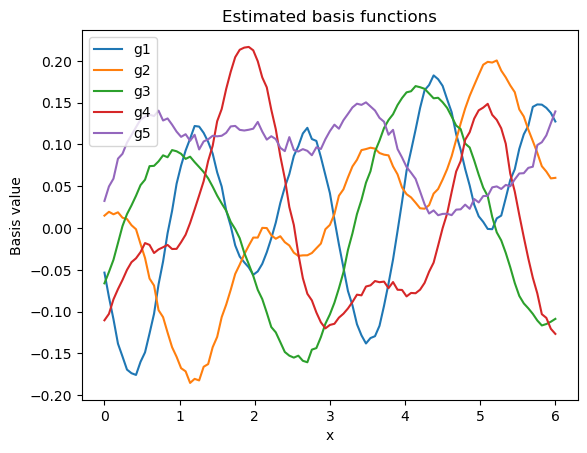

In [5]:
# the five estimated basis functions
plt.figure()
for i in range(F):
    plt.plot(x, pca.components_[i], label=f'g{i + 1}')
plt.xlabel('x')
plt.ylabel('Basis value')
plt.title('Estimated basis functions')
plt.legend()
plt.show()

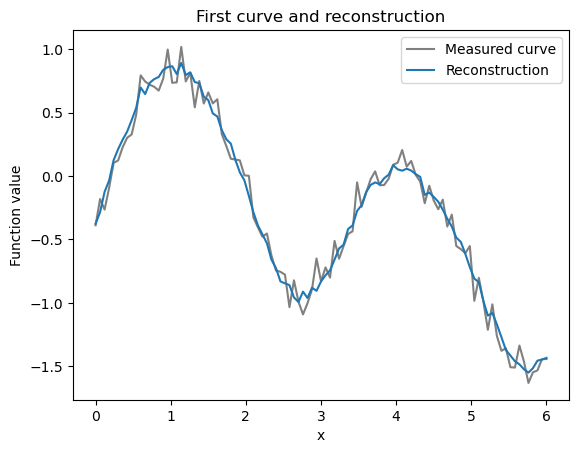

In [6]:
# reconstruct the first curve using its first F PCA weights
weights = pca.transform(functions)
reconstruction = pca.mean_ + weights[0, :F] @ pca.components_[:F]

plt.figure()
plt.plot(x, functions[0], color='grey', label='Measured curve')
plt.plot(x, reconstruction, label='Reconstruction')
plt.xlabel('x')
plt.ylabel('Function value')
plt.title('First curve and reconstruction')
plt.legend()
plt.show()

## Sleep data

In [7]:
# load the training data and apply PCA
X_train = np.loadtxt('data/X_train.csv', delimiter=',')
y_train = np.loadtxt('data/y_train.csv', delimiter=',').astype(int)

sleep_pca = PCA(svd_solver='full').fit(X_train)
scores = sleep_pca.transform(X_train)
sleep_variance = np.cumsum(sleep_pca.explained_variance_ratio_)

print('Components needed for 90% variance:', np.searchsorted(sleep_variance, 0.90) + 1)

Components needed for 90% variance: 5


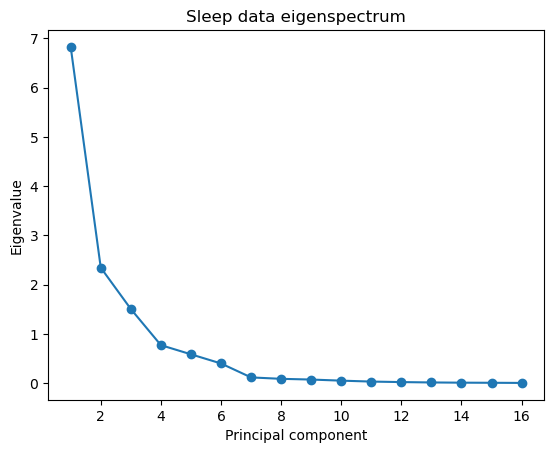

In [8]:
# eigenspectrum
plt.figure()
plt.plot(np.arange(1, X_train.shape[1] + 1), sleep_pca.explained_variance_, 'o-')
plt.xlabel('Principal component')
plt.ylabel('Eigenvalue')
plt.title('Sleep data eigenspectrum')
plt.show()

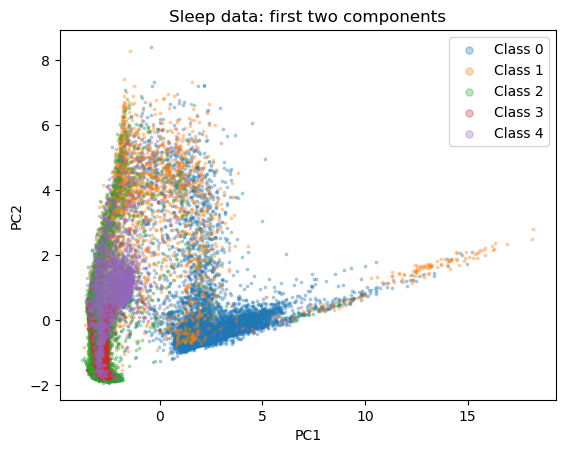

In [9]:
# plot the first two components, using one color per class
plt.figure()
for label in np.unique(y_train):
    points = scores[y_train == label]
    plt.scatter(points[:, 0], points[:, 1], s=3, alpha=0.3, label=f'Class {label}')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Sleep data: first two components')
plt.legend(markerscale=3)
plt.show()

## Gradient descent with PyTorch

In [10]:
def f(x, y):
    return (0.5 * x)**2 + y**2 + 0.5 * x * y

x = torch.tensor(0.9, dtype=torch.float64, requires_grad=True)
y = torch.tensor(0.8, dtype=torch.float64, requires_grad=True)
optimizer = torch.optim.SGD([x, y], lr=0.5)
path = [(x.item(), y.item())]

# take four gradient-descent steps
for _ in range(4):
    optimizer.zero_grad()
    loss = f(x, y)
    loss.backward()
    optimizer.step()
    path.append((x.item(), y.item()))

path = np.array(path)

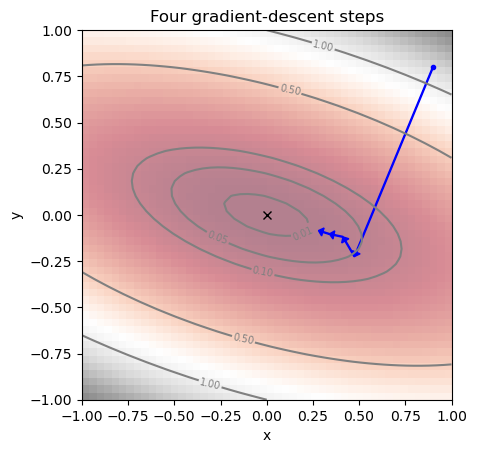

In [11]:
# draw the function and the four steps
grid = np.linspace(-1, 1, 50)
X, Y = np.meshgrid(grid, grid)
Z = f(X, Y)

plt.figure()
plt.imshow(Z, extent=[-1, 1, -1, 1], origin='lower', cmap='RdGy', alpha=0.5)
contours = plt.contour(X, Y, Z, [0.01, 0.05, 0.1, 0.5, 1.0], colors='grey')
plt.clabel(contours, fontsize=7)
plt.plot(0, 0, 'kx')
plt.plot(path[0, 0], path[0, 1], 'bo', markersize=3)
for start, end in zip(path[:-1], path[1:]):
    plt.arrow(*start, *(end - start), color='blue', width=0.005,
              head_width=0.045, head_length=0.025, length_includes_head=True)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Four gradient-descent steps')
plt.show()